In [1]:
# # FINAURA – USD/INR Data Preprocessing

# This notebook performs complete preprocessing of the USD/INR exchange rate dataset.

# ## Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Analysis
# 6. Date Sorting
# 7. Price Validation
# 8. Return Calculation
# 9. Log Return Calculation
# 10. Intraday Return
# 11. Price Range
# 12. Moving Averages
# 13. Rolling Volatility
# 14. Momentum
# 15. Drawdown
# 16. Next 5-Day Volatility Target
# 17. Leakage Check
# 18. Final Validation
# 19. Data Visualization
# 20. Export Processed Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "usd_inr_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "usd_inr_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\usd_inr_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\usd_inr_processed.csv


In [4]:
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 2515
Columns: 7


,Date,Adj Close,Close,High,Low,Open,Volume
0,2017-01-02,67.9448,67.9448,68.2400,67.9000,67.9448,0
1,2017-01-03,68.1339,68.1339,68.4300,68.0380,68.1350,0
2,2017-01-04,68.2698,68.2698,68.2800,67.9345,68.2700,0
3,2017-01-05,67.8855,67.8855,67.9905,67.7150,67.8850,0
4,2017-01-06,67.7330,67.7330,68.1020,67.7335,67.7380,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2515 entries, 0 to 2514
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2515 non-null   object 
 1   Adj Close  2515 non-null   float64
 2   Close      2515 non-null   float64
 3   High       2515 non-null   float64
 4   Low        2515 non-null   float64
 5   Open       2515 non-null   float64
 6   Volume     2515 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 137.7+ KB


In [6]:
df.describe()

,Adj Close,Close,High,Low,Open,Volume
count,2515.0000,2515.0000,2515.0000,2515.0000,2515.0000,2515.0000
mean,77.2463,77.2463,77.4456,77.0085,77.2343,0.0000
std,8.3269,8.3269,8.3363,8.3041,8.3374,0.0000
min,63.2650,63.2650,63.4200,63.2100,63.2650,0.0000
25%,71.1025,71.1025,71.3000,70.8505,71.0876,0.0000
50%,75.4086,75.4086,75.6900,75.0567,75.4272,0.0000
75%,83.3456,83.3456,83.4174,83.2293,83.3456,0.0000
max,96.8769,96.8769,97.0541,96.4598,96.8769,0.0000


In [7]:
print(df.columns.tolist())

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [8]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


In [9]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [10]:
numeric_columns = [
    "open",
    "high",
    "low",
    "close"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2515 entries, 0 to 2514
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       2515 non-null   datetime64[ns]
 1   adj_close  2515 non-null   float64       
 2   close      2515 non-null   float64       
 3   high       2515 non-null   float64       
 4   low        2515 non-null   float64       
 5   open       2515 non-null   float64       
 6   volume     2515 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 137.7 KB


In [11]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
adj_close,0,0.0000
close,0,0.0000
high,0,0.0000
low,0,0.0000
open,0,0.0000
volume,0,0.0000


In [12]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

Duplicate rows: 0
Duplicate dates: 0


In [13]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["date"],
    keep="first"
)

print(
    "Rows after duplicate removal:",
    len(df)
)

Rows after duplicate removal: 2515


In [14]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

Invalid dates: 0


In [15]:
df = df.dropna(
    subset=["date"]
)

In [16]:
df = df.sort_values(
    "date"
).reset_index(drop=True)

df.head()

,date,adj_close,close,high,low,open,volume
0,2017-01-02,67.9448,67.9448,68.2400,67.9000,67.9448,0
1,2017-01-03,68.1339,68.1339,68.4300,68.0380,68.1350,0
2,2017-01-04,68.2698,68.2698,68.2800,67.9345,68.2700,0
3,2017-01-05,67.8855,67.8855,67.9905,67.7150,67.8850,0
4,2017-01-06,67.7330,67.7330,68.1020,67.7335,67.7380,0


In [17]:
print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

Start date: 2017-01-02 00:00:00
End date: 2026-09-02 00:00:00


In [18]:
core_columns = [
    "open",
    "high",
    "low",
    "close"
]

print(
    df[core_columns]
    .isnull()
    .sum()
)

open     0
high     0
low      0
close    0
dtype: int64


In [19]:
df = df.dropna(
    subset=core_columns
).reset_index(drop=True)

print(
    "Rows remaining:",
    len(df)
)

Rows remaining: 2515


In [20]:
for col in core_columns:

    invalid = (
        df[col] <= 0
    ).sum()

    print(
        f"{col}: {invalid} invalid values"
    )

open: 0 invalid values
high: 0 invalid values
low: 0 invalid values
close: 0 invalid values


In [21]:
for col in core_columns:
    df = df[df[col] > 0].copy()

In [22]:
invalid_ohlc = (
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"]) |
    (df["high"] < df["low"])
)

print(
    "Invalid OHLC rows:",
    invalid_ohlc.sum()
)

Invalid OHLC rows: 101


In [23]:
df = df[
    ~invalid_ohlc
].copy()

print(
    "Rows after OHLC validation:",
    len(df)
)

Rows after OHLC validation: 2414


In [24]:
df["daily_return"] = (
    df["close"].pct_change()
)

df[
    [
        "date",
        "close",
        "daily_return"
    ]
].head(10)

,date,close,daily_return
0,2017-01-02,67.9448,NaN
1,2017-01-03,68.1339,0.0028
2,2017-01-04,68.2698,0.0020
3,2017-01-05,67.8855,-0.0056
5,2017-01-09,68.1426,0.0038
6,2017-01-10,68.0970,-0.0007
7,2017-01-11,68.3180,0.0032
8,2017-01-12,68.1400,-0.0026
9,2017-01-13,68.1295,-0.0002
10,2017-01-16,68.1578,0.0004


In [25]:
df["log_return"] = (
    np.log(
        df["close"] /
        df["close"].shift(1)
    )
)

df[
    [
        "date",
        "close",
        "log_return"
    ]
].head(10)

,date,close,log_return
0,2017-01-02,67.9448,NaN
1,2017-01-03,68.1339,0.0028
2,2017-01-04,68.2698,0.0020
3,2017-01-05,67.8855,-0.0056
5,2017-01-09,68.1426,0.0038
6,2017-01-10,68.0970,-0.0007
7,2017-01-11,68.3180,0.0032
8,2017-01-12,68.1400,-0.0026
9,2017-01-13,68.1295,-0.0002
10,2017-01-16,68.1578,0.0004


In [26]:
df["intraday_return"] = (
    (df["close"] - df["open"])
    / df["open"]
)

df[
    [
        "date",
        "intraday_return"
    ]
].head()

,date,intraday_return
0,2017-01-02,0.0000
1,2017-01-03,-0.0000
2,2017-01-04,-0.0000
3,2017-01-05,0.0000
5,2017-01-09,0.0001


In [27]:
df["price_range"] = (
    (df["high"] - df["low"])
    / df["close"]
)

df[
    [
        "date",
        "price_range"
    ]
].head()

,date,price_range
0,2017-01-02,0.0050
1,2017-01-03,0.0058
2,2017-01-04,0.0051
3,2017-01-05,0.0041
5,2017-01-09,0.0027


In [28]:
for window in [5, 10, 20, 50]:

    df[f"ma_{window}"] = (
        df["close"]
        .rolling(window)
        .mean()
    )

In [29]:
df[
    [
        "date",
        "close",
        "ma_5",
        "ma_20",
        "ma_50"
    ]
].tail(10)

,date,close,ma_5,ma_20,ma_50
2505,2026-08-20,95.4960,95.5716,95.5820,95.4789
2506,2026-08-21,95.7722,95.6458,95.5268,95.4791
2507,2026-08-24,95.7003,95.6958,95.4834,95.4909
2508,2026-08-25,95.7231,95.7016,95.4809,95.5106
2509,2026-08-26,93.5461,95.2475,95.3782,95.4837
2510,2026-08-27,95.4303,95.2344,95.3633,95.4951
2511,2026-08-28,95.4704,95.1740,95.3526,95.5177
2512,2026-08-31,95.3803,95.1100,95.3515,95.5387
2513,2026-09-01,95.1144,94.9883,95.3406,95.5470
2514,2026-09-02,94.9552,95.2701,95.3335,95.5425


In [30]:
for window in [5, 10, 20]:

    df[f"volatility_{window}d"] = (
        df["log_return"]
        .rolling(window)
        .std()
        * np.sqrt(252)
    )

In [31]:
df[
    [
        "date",
        "volatility_5d",
        "volatility_10d",
        "volatility_20d"
    ]
].tail(10)

,date,volatility_5d,volatility_10d,volatility_20d
2505,2026-08-20,0.0350,0.0286,0.0423
2506,2026-08-21,0.0396,0.0295,0.0418
2507,2026-08-24,0.0412,0.0291,0.0407
2508,2026-08-25,0.0371,0.0280,0.0284
2509,2026-08-26,0.1654,0.1207,0.0864
2510,2026-08-27,0.2428,0.1636,0.1141
2511,2026-08-28,0.2415,0.1636,0.1141
2512,2026-08-31,0.2415,0.1636,0.1137
2513,2026-09-01,0.2417,0.1634,0.1141
2514,2026-09-02,0.1516,0.1631,0.1139


In [32]:
df["momentum_5d"] = (
    df["close"] /
    df["close"].shift(5) - 1
)

df["momentum_20d"] = (
    df["close"] /
    df["close"].shift(20) - 1
)

df[
    [
        "date",
        "momentum_5d",
        "momentum_20d"
    ]
].tail()

,date,momentum_5d,momentum_20d
2510,2026-08-27,-0.0007,-0.0031
2511,2026-08-28,-0.0032,-0.0022
2512,2026-08-31,-0.0033,-0.0002
2513,2026-09-01,-0.0064,-0.0023
2514,2026-09-02,0.0151,-0.0015


In [33]:
df["running_max"] = (
    df["close"].cummax()
)

df["drawdown"] = (
    df["close"] /
    df["running_max"] - 1
)

df.drop(
    columns=["running_max"],
    inplace=True
)

df[
    [
        "date",
        "close",
        "drawdown"
    ]
].tail()

,date,close,drawdown
2510,2026-08-27,95.4303,-0.0149
2511,2026-08-28,95.4704,-0.0145
2512,2026-08-31,95.3803,-0.0154
2513,2026-09-01,95.1144,-0.0182
2514,2026-09-02,94.9552,-0.0198


In [34]:
df["previous_close"] = (
    df["close"].shift(1)
)

df[
    [
        "date",
        "close",
        "previous_close"
    ]
].tail(10)

,date,close,previous_close
2505,2026-08-20,95.4960,95.8164
2506,2026-08-21,95.7722,95.4960
2507,2026-08-24,95.7003,95.7722
2508,2026-08-25,95.7231,95.7003
2509,2026-08-26,93.5461,95.7231
2510,2026-08-27,95.4303,93.5461
2511,2026-08-28,95.4704,95.4303
2512,2026-08-31,95.3803,95.4704
2513,2026-09-01,95.1144,95.3803
2514,2026-09-02,94.9552,95.1144


In [35]:
df["change"] = (
    df["close"] -
    df["previous_close"]
)

df["change_pct"] = (
    df["daily_return"] * 100
)

df[
    [
        "date",
        "change",
        "change_pct"
    ]
].tail(10)

,date,change,change_pct
2505,2026-08-20,-0.3204,-0.3344
2506,2026-08-21,0.2762,0.2892
2507,2026-08-24,-0.0719,-0.0751
2508,2026-08-25,0.0228,0.0238
2509,2026-08-26,-2.1770,-2.2743
2510,2026-08-27,1.8842,2.0142
2511,2026-08-28,0.0401,0.0420
2512,2026-08-31,-0.0901,-0.0944
2513,2026-09-01,-0.2659,-0.2788
2514,2026-09-02,-0.1592,-0.1674


In [36]:
future_returns = pd.concat(
    [
        df["log_return"].shift(-i)
        for i in range(1, 6)
    ],
    axis=1
)

future_returns.columns = [
    f"_future_return_{i}"
    for i in range(1, 6)
]

df["target_5d_volatility"] = (
    future_returns.std(axis=1)
    * np.sqrt(252)
)

future_returns.head()

,_future_return_1,_future_return_2,_future_return_3,_future_return_4,_future_return_5
0,0.0028,0.0020,-0.0056,0.0038,-0.0007
1,0.0020,-0.0056,0.0038,-0.0007,0.0032
2,-0.0056,0.0038,-0.0007,0.0032,-0.0026
3,0.0038,-0.0007,0.0032,-0.0026,-0.0002
5,-0.0007,0.0032,-0.0026,-0.0002,0.0004


In [37]:
df[
    [
        "date",
        "close",
        "volatility_20d",
        "target_5d_volatility"
    ]
].tail(15)

,date,close,volatility_20d,target_5d_volatility
2500,2026-08-13,95.3443,0.0435,0.0350
2501,2026-08-14,95.4012,0.0430,0.0396
2502,2026-08-17,95.4503,0.0415,0.0412
2503,2026-08-18,95.6941,0.0419,0.0371
2504,2026-08-19,95.8164,0.0421,0.1654
2505,2026-08-20,95.4960,0.0423,0.2428
2506,2026-08-21,95.7722,0.0418,0.2415
2507,2026-08-24,95.7003,0.0407,0.2415
2508,2026-08-25,95.7231,0.0284,0.2417
2509,2026-08-26,93.5461,0.0864,0.1516


In [38]:
target = "target_5d_volatility"

feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown",
    "previous_close",
    "change",
    "change_pct"
]

print(
    "Number of features:",
    len(feature_columns)
)

print(
    "Target:",
    target
)

print(
    "Target included in features:",
    target in feature_columns
)

Number of features: 21
Target: target_5d_volatility
Target included in features: False


In [39]:
print(
    "Temporary future-return columns were stored separately."
)

print(
    "Target calculation completed successfully."
)

Temporary future-return columns were stored separately.
Target calculation completed successfully.


In [40]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 148


In [41]:
df = df.dropna().reset_index(
    drop=True
)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [42]:
print("========== FINAL DATASET ==========")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

========== FINAL DATASET ==========
Rows: 2363
Columns: 25
Start date: 2017-03-14 00:00:00
End date: 2026-08-31 00:00:00
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0


In [43]:
for i, col in enumerate(
    df.columns,
    1
):
    print(
        i,
        "-",
        col
    )

1 - date
2 - adj_close
3 - close
4 - high
5 - low
6 - open
7 - volume
8 - daily_return
9 - log_return
10 - intraday_return
11 - price_range
12 - ma_5
13 - ma_10
14 - ma_20
15 - ma_50
16 - volatility_5d
17 - volatility_10d
18 - volatility_20d
19 - momentum_5d
20 - momentum_20d
21 - drawdown
22 - previous_close
23 - change
24 - change_pct
25 - target_5d_volatility


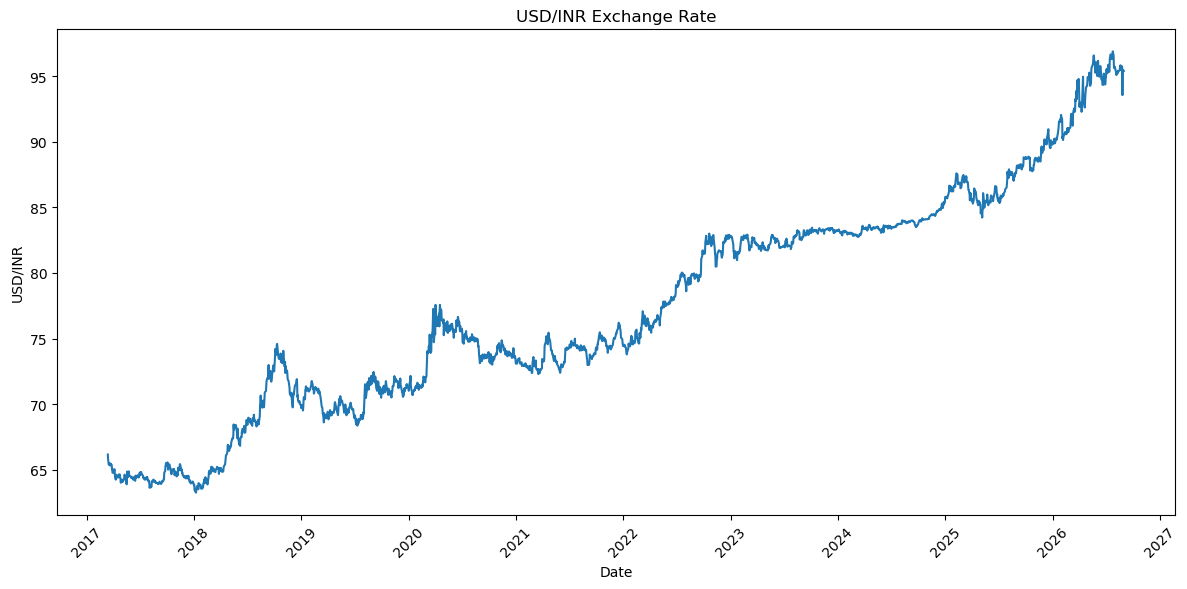

In [44]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["close"]
)

plt.title(
    "USD/INR Exchange Rate"
)

plt.xlabel("Date")
plt.ylabel("USD/INR")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [45]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    "Processed USD/INR dataset saved successfully!"
)

print(
    "Location:",
    OUTPUT_FILE
)

print(
    "Rows:",
    len(df)
)

print(
    "Columns:",
    len(df.columns)
)

Processed USD/INR dataset saved successfully!
Location: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\usd_inr_processed.csv
Rows: 2363
Columns: 25
